In [1]:
import pandas as pd

In [3]:
import zipfile

In [29]:
#Data Cleaning
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
df=df.drop_duplicates()

OrderID          0
OrderDate        0
CustomerID       0
CustomerName     0
ProductID        0
ProductName      0
Category         0
Brand            0
Quantity         0
UnitPrice        0
Discount         0
Tax              0
ShippingCost     0
TotalAmount      0
PaymentMethod    0
OrderStatus      0
City             0
State            0
Country          0
SellerID         0
dtype: int64
Duplicate rows: 0


In [7]:
df=pd.read_csv('Amazon.csv')
print(df.shape)
df.head()

(100000, 20)


,OrderID,OrderDate,CustomerID,CustomerName,ProductID,ProductName,Category,Brand,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount,PaymentMethod,OrderStatus,City,State,Country,SellerID
0,ORD0000001,2023-01-31,CUST001504,Vihaan Sharma,P00014,Drone Mini,Books,BrightLux,3,106.59,0.00,0.00,0.09,319.86,Debit Card,Delivered,Washington,DC,India,SELL01967
1,ORD0000002,2023-12-30,CUST000178,Pooja Kumar,P00040,Microphone,Home & Kitchen,UrbanStyle,1,251.37,0.05,19.10,1.74,259.64,Amazon Pay,Delivered,Fort Worth,TX,United States,SELL01298
2,ORD0000003,2022-05-10,CUST047516,Sneha Singh,P00044,Power Bank 20000mAh,Clothing,UrbanStyle,3,35.03,0.10,7.57,5.91,108.06,Debit Card,Delivered,Austin,TX,United States,SELL00908
3,ORD0000004,2023-07-18,CUST030059,Vihaan Reddy,P00041,Webcam Full HD,Home & Kitchen,Zenith,5,33.58,0.15,11.42,5.53,159.66,Cash on Delivery,Delivered,Charlotte,NC,India,SELL01164
4,ORD0000005,2023-02-04,CUST048677,Aditya Kapoor,P00029,T-Shirt,Clothing,KiddoFun,2,515.64,0.25,38.67,9.23,821.36,Credit Card,Cancelled,San Antonio,TX,Canada,SELL01411


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   OrderID        100000 non-null  object 
 1   OrderDate      100000 non-null  object 
 2   CustomerID     100000 non-null  object 
 3   CustomerName   100000 non-null  object 
 4   ProductID      100000 non-null  object 
 5   ProductName    100000 non-null  object 
 6   Category       100000 non-null  object 
 7   Brand          100000 non-null  object 
 8   Quantity       100000 non-null  int64  
 9   UnitPrice      100000 non-null  float64
 10  Discount       100000 non-null  float64
 11  Tax            100000 non-null  float64
 12  ShippingCost   100000 non-null  float64
 13  TotalAmount    100000 non-null  float64
 14  PaymentMethod  100000 non-null  object 
 15  OrderStatus    100000 non-null  object 
 16  City           100000 non-null  object 
 17  State          100000 non-null

In [9]:
df.describe()

,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,3.001400,302.905748,0.074226,68.468902,7.406660,918.256479
std,1.413548,171.840797,0.082583,74.131180,4.324057,724.508332
min,1.000000,5.000000,0.000000,0.000000,0.000000,4.270000
25%,2.000000,154.190000,0.000000,15.920000,3.680000,340.890000
50%,3.000000,303.070000,0.050000,45.250000,7.300000,714.315000
75%,4.000000,451.500000,0.100000,96.060000,11.150000,1349.765000
max,5.000000,599.990000,0.300000,538.460000,15.000000,3534.980000


In [10]:
df['Category'].value_counts()

,count
Category,
Electronics,16853
Sports & Outdoors,16804
Books,16752
Home & Kitchen,16610
Toys & Games,16542
Clothing,16439


In [11]:
df.groupby('Category')['TotalAmount'].sum().sort_values(ascending=False)

,TotalAmount
Category,
Electronics,15584217.18
Sports & Outdoors,15345571.88
Books,15261837.01
Clothing,15253397.50
Toys & Games,15216684.99
Home & Kitchen,15163939.36


In [12]:
# How do people pay?
df['PaymentMethod'].value_counts()

,count
PaymentMethod,
Credit Card,35038
Debit Card,20024
UPI,15066
Amazon Pay,15017
Net Banking,9927
Cash on Delivery,4928


In [13]:
df['OrderStatus'].value_counts()

,count
OrderStatus,
Delivered,74628
Shipped,15192
Pending,4103
Returned,3049
Cancelled,3028


In [14]:
df.groupby('State')['TotalAmount'].sum().sort_values(ascending=False).head(10)

,TotalAmount
State,
TX,22862540.54
CA,18231196.79
NC,4747701.73
WA,4660962.17
PA,4650673.88
CO,4638498.97
IL,4632847.44
OH,4615442.32
IN,4609048.43


In [16]:
#1. what are the top 10?
df.groupby('ProductName')['TotalAmount'].sum().sort_values(ascending=False).head(10)

,TotalAmount
ProductName,
Memory Card 128GB,1935138.40
LED Desk Lamp,1921948.41
Mechanical Keyboard,1906963.54
Electric Kettle,1905751.79
Smartwatch,1901275.59
Dress Shirt,1896765.36
Water Bottle,1895467.95
Gaming Mouse,1895103.98
Kids Toy Car,1891082.43


<Axes: xlabel='OrderDate'>

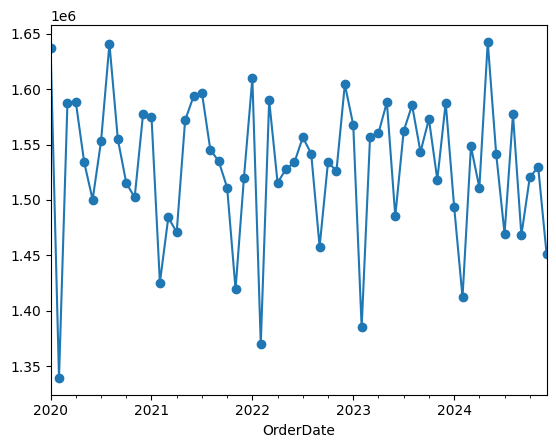

In [20]:
#2. Mouthly sales
df['OrderDate']= pd.to_datetime(df['OrderDate'])
monthly= df.groupby(df['OrderDate'].dt.to_period('M'))['TotalAmount'].sum()
monthly.plot(kind='line', marker='o')

In [21]:
df[['Discount', 'TotalAmount', 'Quantity']].corr()

,Discount,TotalAmount,Quantity
Discount,1.000000,-0.108088,-0.000398
TotalAmount,-0.108088,1.000000,0.594928
Quantity,-0.000398,0.594928,1.000000


In [22]:
# Desciptive Statitics
df[['TotalAmount', 'Quantity', 'Discount']].describe()

,TotalAmount,Quantity,Discount
count,100000.000000,100000.000000,100000.000000
mean,918.256479,3.001400,0.074226
std,724.508332,1.413548,0.082583
min,4.270000,1.000000,0.000000
25%,340.890000,2.000000,0.000000
50%,714.315000,3.000000,0.050000
75%,1349.765000,4.000000,0.100000
max,3534.980000,5.000000,0.300000


<Axes: title={'center': 'Total Sales by State'}, xlabel='State', ylabel='Total Sale ($)'>

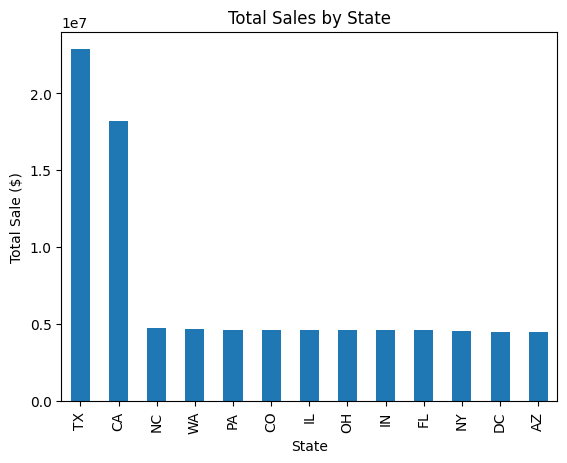

In [23]:
# Visulations
state_sales=df.groupby('State')['TotalAmount'].sum().sort_values(ascending=False)
state_sales.plot(kind='bar', title='Total Sales by State', xlabel='State', ylabel='Total Sale ($)')

<Axes: title={'center': 'Total Sales by Payment Method'}, xlabel='Payment Method', ylabel='Total Sales($)'>

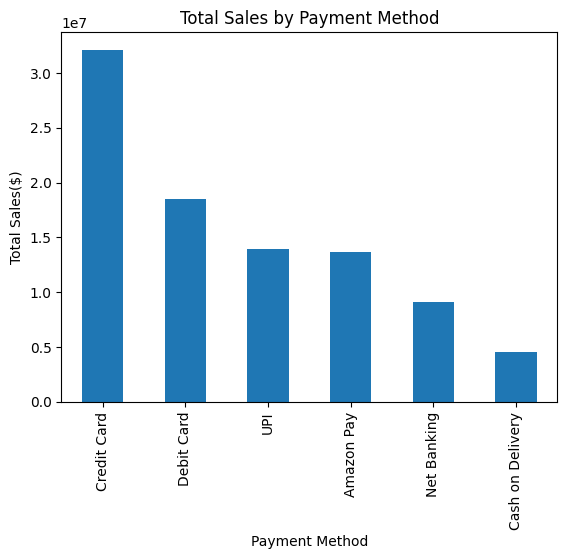

In [27]:
# Visulation 3
payment_sales=df.groupby('PaymentMethod')['TotalAmount'].sum().sort_values(ascending=False)
payment_sales.plot(kind='bar', title='Total Sales by Payment Method', xlabel='Payment Method', ylabel='Total Sales($)')

<Axes: xlabel='OrderDate'>

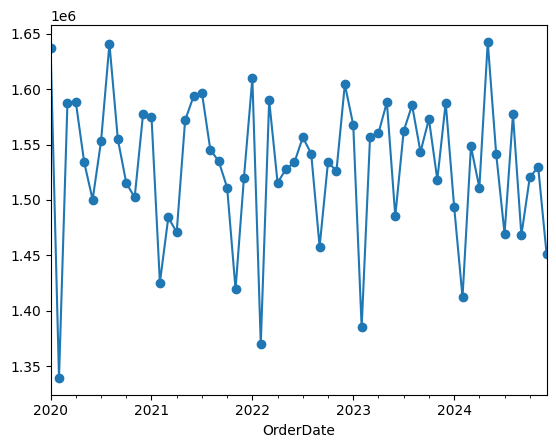

In [28]:
df['OrderDate']= pd.to_datetime(df['OrderDate'])
monthly= df.groupby(df['OrderDate'].dt.to_period('M'))['TotalAmount'].sum()
monthly.plot(kind='line', marker='o')